<a href="https://colab.research.google.com/github/urazovandriy-dotcom/ML_LABS_2026/blob/main/%D0%9B%D0%A010_%D0%A3%D1%80%D0%B0%D0%B7%D0%BE%D0%B2_3_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота №11
Нейронна мережа для розпізнавання дорожніх знаків.

1. Перевірка GPU, імпорт бібліотек та завантаження датасету GTSRB

In [2]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import kagglehub
from sklearn.model_selection import train_test_split
print(f"TensorFlow version: {tf.__version__}")
gpus = tf.config.list_physical_devices("GPU")
print(f"Доступні GPU: {gpus if gpus else 'GPU не знайдено (використовується CPU)'}")
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
path = kagglehub.dataset_download("meowmeowmeowmeowmeow/gtsrb-german-traffic-sign")
print("Path to dataset files:", path)
print("Вміст директорії:", os.listdir(path))
train_df = pd.read_csv(os.path.join(path, "Train.csv"))
test_df = pd.read_csv(os.path.join(path, "Test.csv"))
print(f"\nКількість записів у Train.csv: {len(train_df)}")
print(f"Кількість записів у Test.csv:  {len(test_df)}")
print(f"Кількість класів: {train_df['ClassId'].nunique()}")

TensorFlow version: 2.21.0
Доступні GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Using Colab cache for faster access to the 'gtsrb-german-traffic-sign' dataset.
Path to dataset files: /kaggle/input/gtsrb-german-traffic-sign
Вміст директорії: ['Meta', 'meta', 'Meta.csv', 'Train.csv', 'Test.csv', 'Test', 'test', 'Train', 'train']

Кількість записів у Train.csv: 39209
Кількість записів у Test.csv:  12630
Кількість класів: 43


2. Підготовка вибірок, нормалізація та EDA

Завантаження та обробка зображень...
X_train: (31367, 48, 48, 3), y_train: (31367,)
X_val:   (7842, 48, 48, 3),   y_val:   (7842,)
X_test:  (12630, 48, 48, 3),  y_test:  (12630,)
Діапазон пікселів: [0.0, 1.0]


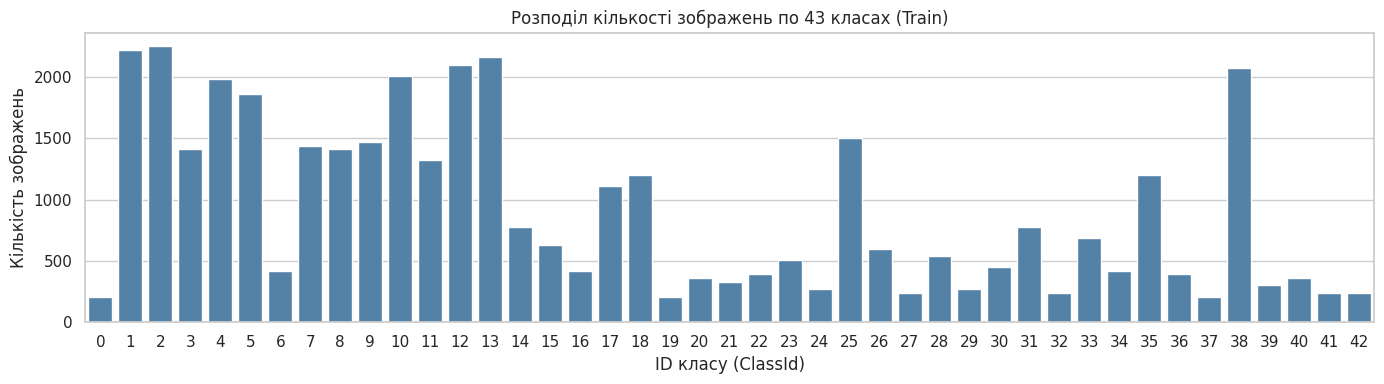

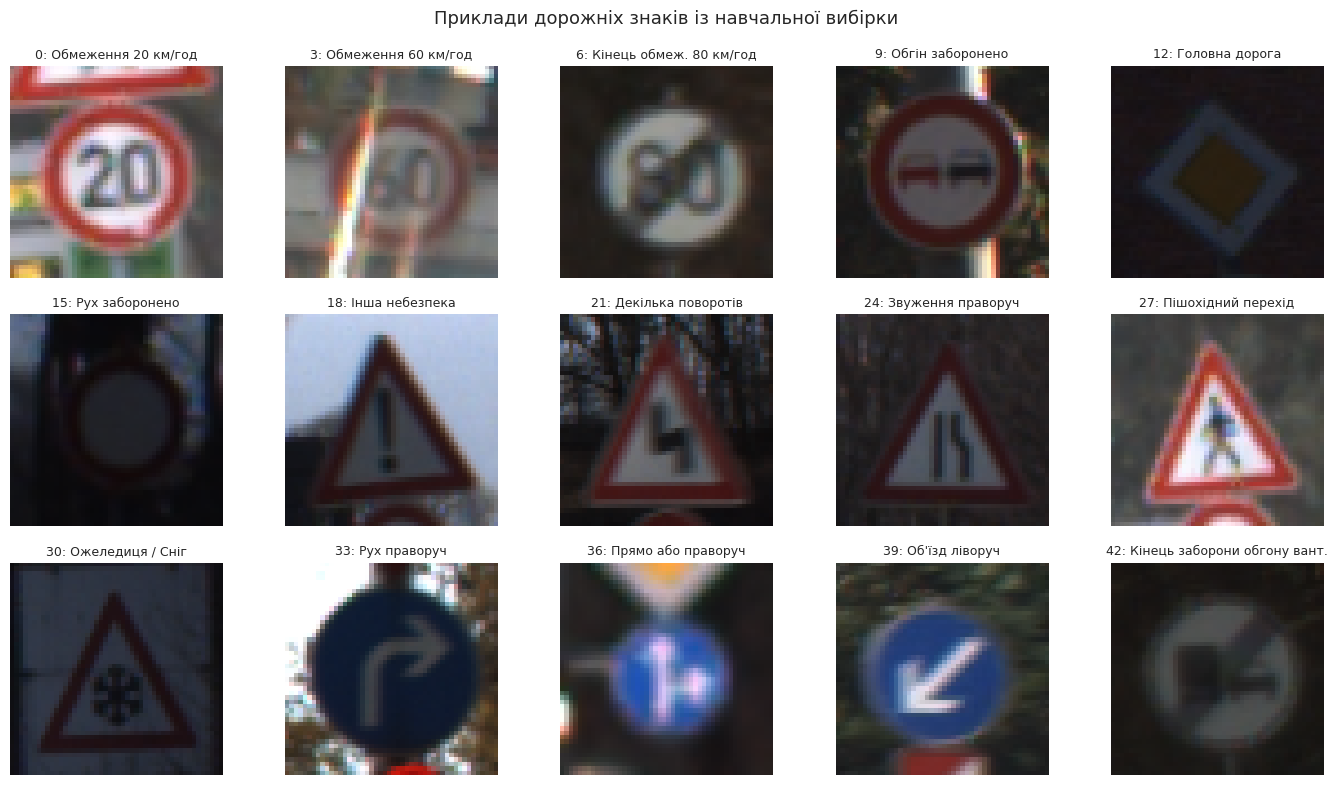

In [4]:
IMG_SIZE = 48
NUM_CLASSES = 43
CLASSES = {
    0: "Обмеження 20 км/год", 1: "Обмеження 30 км/год", 2: "Обмеження 50 км/год",
    3: "Обмеження 60 км/год", 4: "Обмеження 70 км/год", 5: "Обмеження 80 км/год",
    6: "Кінець обмеж. 80 км/год", 7: "Обмеження 100 км/год", 8: "Обмеження 120 км/год",
    9: "Обгін заборонено", 10: "Обгін вантажівкам заборонено", 11: "Перехрестя з другорядною",
    12: "Головна дорога", 13: "Дати дорогу", 14: "STOP",
    15: "Рух заборонено", 16: "Рух вантажівок заборонено", 17: "В'їзд заборонено",
    18: "Інша небезпека", 19: "Поворот ліворуч", 20: "Поворот праворуч",
    21: "Декілька поворотів", 22: "Нерівна дорога", 23: "Слизька дорога",
    24: "Звуження праворуч", 25: "Дорожні роботи", 26: "Світлофор",
    27: "Пішохідний перехід", 28: "Діти", 29: "Велосипедисти",
    30: "Ожеледиця / Сніг", 31: "Дикі тварини", 32: "Кінець усіх обмежень",
    33: "Рух праворуч", 34: "Рух ліворуч", 35: "Рух прямо",
    36: "Прямо або праворуч", 37: "Прямо або ліворуч", 38: "Об'їзд праворуч",
    39: "Об'їзд ліворуч", 40: "Круговий рух", 41: "Кінець заборони обгону",
    42: "Кінець заборони обгону вант."
}
from concurrent.futures import ThreadPoolExecutor
def _read_single_image(args):
    img_path, img_size = args
    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    return cv2.resize(img, (img_size, img_size))
def load_images_fast(df_meta, base_path, img_size=IMG_SIZE):
    tasks = [(os.path.join(base_path, p), img_size) for p in df_meta["Path"]]
    with ThreadPoolExecutor(max_workers=8) as executor:
        images = list(executor.map(_read_single_image, tasks))
    X = np.array(images, dtype=np.uint8)
    y = df_meta["ClassId"].values
    return X, y
print("Завантаження та обробка зображень...")
X_all, y_all = load_images(train_df, path)
X_test, y_test = load_images(test_df, path)
X_train, X_val, y_train, y_val = train_test_split(
    X_all, y_all, test_size=0.2, random_state=42, stratify=y_all
)
print(f"X_train: {X_train.shape}, y_train: {y_train.shape}")
print(f"X_val:   {X_val.shape},   y_val:   {y_val.shape}")
print(f"X_test:  {X_test.shape},  y_test:  {y_test.shape}")
print(f"Діапазон пікселів: [{X_train.min():.1f}, {X_train.max():.1f}]")
plt.figure(figsize=(14, 4))
class_counts = pd.Series(y_all).value_counts().sort_index()
sns.barplot(x=class_counts.index, y=class_counts.values, color="steelblue")
plt.title("Розподіл кількості зображень по 43 класах (Train)")
plt.xlabel("ID класу (ClassId)")
plt.ylabel("Кількість зображень")
plt.tight_layout()
plt.show()
unique_classes = np.linspace(0, NUM_CLASSES - 1, 15, dtype=int)
fig, axes = plt.subplots(3, 5, figsize=(14, 8))
for ax, cls_id in zip(axes.flat, unique_classes):
    idx = np.where(y_train == cls_id)[0][0]
    ax.imshow(X_train[idx])
    ax.set_title(f"{cls_id}: {CLASSES[cls_id]}", fontsize=9)
    ax.axis("off")
plt.suptitle("Приклади дорожніх знаків із навчальної вибірки", fontsize=13)
plt.tight_layout()
plt.show()

3. Побудова архітектури CNN з аугментацією даних

In [7]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input, Rescaling, Conv2D, MaxPooling2D, BatchNormalization,
    Dropout, Flatten, Dense,
    RandomRotation, RandomZoom, RandomTranslation
)
from tensorflow.keras.optimizers import Adam
data_augmentation = Sequential([
    RandomRotation(0.08),
    RandomZoom(0.1),
    RandomTranslation(0.1, 0.1)
], name="data_augmentation")
model = Sequential([
    Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
    Rescaling(1./255),
    data_augmentation,
    Conv2D(32, (3, 3), padding="same", activation="relu"),
    BatchNormalization(),
    Conv2D(32, (3, 3), padding="same", activation="relu"),
    BatchNormalization(),
    MaxPooling2D((2, 2)),
    Dropout(0.2),
    Conv2D(64, (3, 3), padding="same", activation="relu"),
    BatchNormalization(),
    Conv2D(64, (3, 3), padding="same", activation="relu"),
    BatchNormalization(),
    MaxPooling2D((2, 2)),
    Dropout(0.25),
    Conv2D(128, (3, 3), padding="same", activation="relu"),
    BatchNormalization(),
    Conv2D(128, (3, 3), padding="same", activation="relu"),
    BatchNormalization(),
    MaxPooling2D((2, 2)),
    Dropout(0.3),
    Flatten(),
    Dense(256, activation="relu"),
    BatchNormalization(),
    Dropout(0.4),
    Dense(NUM_CLASSES, activation="softmax")
])
model.compile(
    optimizer=Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 48, 48, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 48, 48, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 48, 48, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 48, 48, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 48, 48, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 48, 48, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 24, 24, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 24, 24, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 24, 24, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 24, 24, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 12, 12, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 12, 12, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_12          │ (None, 12, 12, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │     1,179,90

 Total params: 1,480,779 (5.65 MB)

 Trainable params: 1,479,371 (5.64 MB)

 Non-trainable params: 1,408 (5.50 KB)

4. Навчання моделі з колбеками

In [8]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=6,
    restore_best_weights=True,
    verbose=1
)
reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=1e-6,
    verbose=1
)
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=25,
    batch_size=64,
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)

Epoch 1/25
491/491 ━━━━━━━━━━━━━━━━━━━━ 25s 38ms/step - accuracy: 0.4503 - loss: 1.9752 - val_accuracy: 0.3030 - val_loss: 2.6584 - learning_rate: 0.0010
Epoch 2/25
491/491 ━━━━━━━━━━━━━━━━━━━━ 19s 39ms/step - accuracy: 0.8425 - loss: 0.5068 - val_accuracy: 0.8460 - val_loss: 0.8670 - learning_rate: 0.0010
Epoch 3/25
491/491 ━━━━━━━━━━━━━━━━━━━━ 18s 37ms/step - accuracy: 0.9343 - loss: 0.2183 - val_accuracy: 0.9767 - val_loss: 0.0759 - learning_rate: 0.0010
Epoch 4/25
491/491 ━━━━━━━━━━━━━━━━━━━━ 18s 36ms/step - accuracy: 0.9610 - loss: 0.1315 - val_accuracy: 0.9682 - val_loss: 0.1258 - learning_rate: 0.0010
Epoch 5/25
491/491 ━━━━━━━━━━━━━━━━━━━━ 18s 37ms/step - accuracy: 0.9705 - loss: 0.0957 - val_accuracy: 0.9952 - val_loss: 0.0153 - learning_rate: 0.0010
Epoch 6/25
491/491 ━━━━━━━━━━━━━━━━━━━━ 18s 37ms/step - accuracy: 0.9742 - loss: 0.0838 - val_accuracy: 0.9814 - val_loss: 0.0697 - learning_rate: 0.0010
Epoch 7/25
491/491 ━━━━━━━━━━━━━━━━━━━━ 19s 38ms/step - accuracy: 0.9761 - l

5. Криві навчання та оцінка на тестовій вибірці

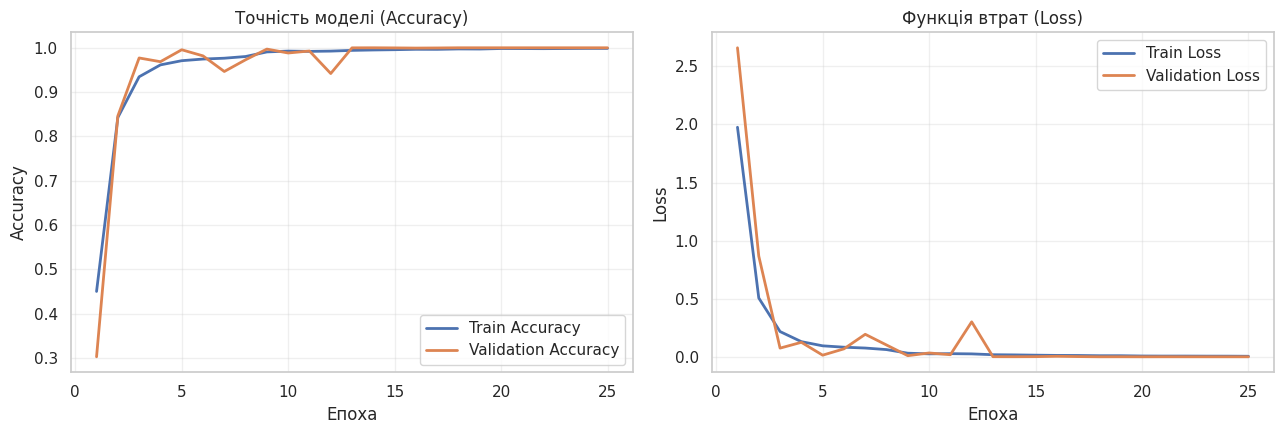

=== Результати на незалежній тестовій вибірці (12630 зображень) ===
Test Loss:     0.0490
Test Accuracy: 0.9865 (98.65%)
Кількість помилок: 170 із 12630


In [9]:
from sklearn.metrics import classification_report, accuracy_score
epochs_range = range(1, len(history.history["loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(epochs_range, history.history["accuracy"], label="Train Accuracy", linewidth=2)
axes[0].plot(epochs_range, history.history["val_accuracy"], label="Validation Accuracy", linewidth=2)
axes[0].set_title("Точність моделі (Accuracy)")
axes[0].set_xlabel("Епоха")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True, alpha=0.3)
axes[1].plot(epochs_range, history.history["loss"], label="Train Loss", linewidth=2)
axes[1].plot(epochs_range, history.history["val_loss"], label="Validation Loss", linewidth=2)
axes[1].set_title("Функція втрат (Loss)")
axes[1].set_xlabel("Епоха")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
test_loss, test_acc = model.evaluate(X_test, y_test, batch_size=64, verbose=0)
y_pred_probs = model.predict(X_test, batch_size=64, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)
errors_count = np.sum(y_pred != y_test)
print(f"=== Результати на незалежній тестовій вибірці ({len(y_test)} зображень) ===")
print(f"Test Loss:     {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.4f} ({test_acc * 100:.2f}%)")
print(f"Кількість помилок: {errors_count} із {len(y_test)}")

6. Візуалізація прогнозів (True vs Predicted)

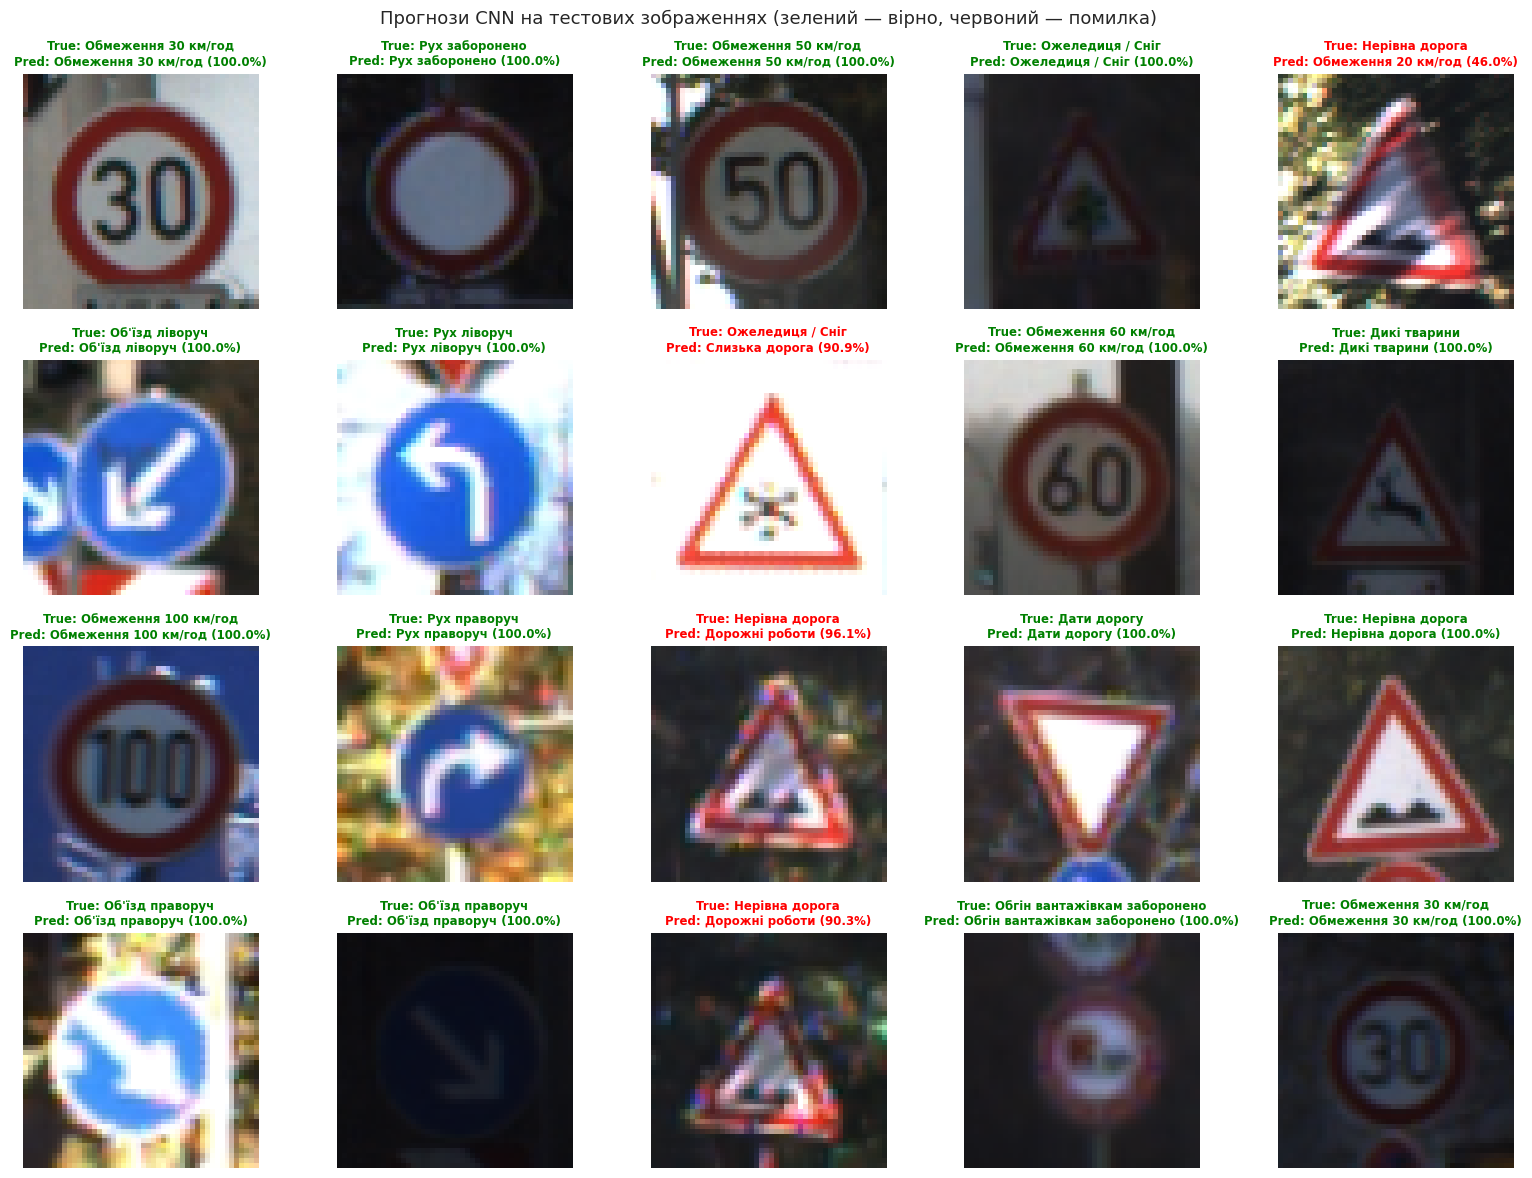

In [11]:
rng = np.random.default_rng(42)
misclassified_idx = np.where(y_pred != y_test)[0]
correct_idx = np.where(y_pred == y_test)[0]
n_err = min(4, len(misclassified_idx))
sample_err = rng.choice(misclassified_idx, size=n_err, replace=False) if n_err > 0 else np.array([], dtype=int)
sample_ok = rng.choice(correct_idx, size=20 - n_err, replace=False)
sample_indices = np.concatenate([sample_err, sample_ok])
rng.shuffle(sample_indices)
fig, axes = plt.subplots(4, 5, figsize=(16, 12))
for ax, idx in zip(axes.flat, sample_indices):
    true_lbl = y_test[idx]
    pred_lbl = y_pred[idx]
    is_correct = (true_lbl == pred_lbl)
    color = "green" if is_correct else "red"
    ax.imshow(X_test[idx])
    conf = y_pred_probs[idx, pred_lbl] * 100
    ax.set_title(
        f"True: {CLASSES[true_lbl]}\nPred: {CLASSES[pred_lbl]} ({conf:.1f}%)",
        color=color,
        fontsize=8.5,
        fontweight="bold"
    )
    ax.axis("off")
plt.suptitle("Прогнози CNN на тестових зображеннях (зелений — вірно, червоний — помилка)", fontsize=13)
plt.tight_layout()
plt.show()

# Висновки

1. **Підготовка даних та EDA:** Під час виконання роботи я проаналізував набір даних **GTSRB** (`39 209` навчальних і `12 630` незалежних тестових зображень, `43` класи дорожніх знаків) та виявив суттєвий дисбаланс класів (від `~200` до `~2250` зображень на клас) і значні відмінності в освітленості та чіткості знімків. Усі зображення я привів до єдиного розміру `48×48` RGB, нормалізував пікселі через шар `Rescaling(1./255)` і виконав стратифіковане розбиття на навчальну (`31 367`) та валідаційну (`7 842`) вибірки без витоку даних.
2. **Архітектура та навчання CNN:** Побудована мною триблочна згорткова нейронна мережа (`1 480 779` параметрів) із шарами `Conv2D`, `BatchNormalization`, `MaxPooling2D`, `Dropout` та безпечною аугментацією (`RandomRotation`, `RandomZoom`, `RandomTranslation` без горизонтального віддзеркалення) показала стабільну збіжність без перенавчання. Завдяки застосуванню `ReduceLROnPlateau` після 12-ї епохи коливання `val_loss` зникли, і на 20-й епосі модель досягла пікових значень `val_accuracy = 0.9996` та `val_loss = 0.0013` (найкращі ваги було відновлено за допомогою `EarlyStopping`).
3. **Оцінка на незалежній тестовій вибірці:** На `12 630` тестових зображеннях (`Test.csv`) мережа продемонструвала високу узагальнювальну здатність, досягнувши `Test Accuracy = 98.65%` (`Test Loss = 0.0490`) і допустивши лише `170` помилок.
4. **Аналіз помилок класифікації:** Візуалізація прогнозів із рівнем упевненості підтвердила, що модель упевнено (`100%`) розпізнає навіть темні й розмиті знаки, а поодинокі хибні класифікації виникають переважно на сильно пошкоджених кадрах (де впевненість знижується, наприклад до `46.0%`) або між візуально схожими трикутними попереджувальними знаками («Нерівна дорога» та «Дорожні роботи», «Ожеледиця / Сніг» та «Слизька дорога»).